
**Preventing Supply Chain Cyberattacks: A Case Study of the SolarWinds Orion Attack**

N=50, runs=1000, p=0.3, noise=0.15
Metric                Baseline (mean ± sd)      Proposed (mean ± sd)      
Detection Time           31.03 ± 19.93           1.37 ± 0.72        
Affected Packages         6.87 ± 11.72           4.08 ± 8.63        
Recovery Time            50.61 ± 1.44            4.70 ± 8.68        
False Positive Rate     86.95% ± 21.65%        16.93% ± 23.95%      


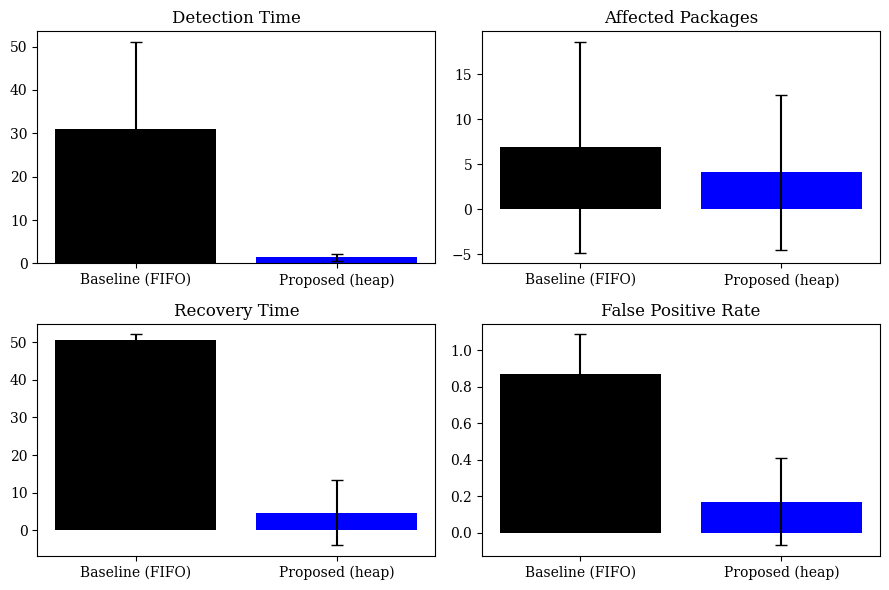

In [1]:
import random
import heapq
import statistics
from collections import deque

import networkx as nx
import matplotlib.pyplot as plt


class Node:
    def __init__(self, node_id):
        self.id = node_id
        self.dependents = []        # graph edges: packages that depend on this node
        self.is_infected = False
        self.is_isolated = False
        self.anomaly_score = 0.0    # moderator's score in [0, 1]


def build_dependency_graph(num_nodes, m=2, seed=None):
    """Step 1: scale-free dependency graph (few popular libraries, many small ones)."""
    g = nx.barabasi_albert_graph(num_nodes, m, seed=seed)
    nodes = [Node(i) for i in range(num_nodes)]
    for u, v in g.edges():
        old, new = (u, v) if u < v else (v, u)
        nodes[old].dependents.append(nodes[new])   # newer package depends on older one
    return nodes


def update_scores(nodes, noise_level, rng):
    """Step 3b: moderator scores every node (infected: high, healthy: low, plus noise)."""
    for n in nodes:
        base = 0.7 if n.is_infected else 0.3
        n.anomaly_score = min(1.0, max(0.0, base + rng.gauss(0, noise_level)))


def run_simulation(nodes, seed_id, infection_prob=0.3, mode="proposed",
                   noise_level=0.15, rng=None, max_steps=1000):
    """Modes: 'baseline' (FIFO queue) or 'proposed' (max-heap on anomaly score)."""
    rng = rng or random.Random()
    for n in nodes:
        n.is_infected = n.is_isolated = False
        n.anomaly_score = 0.0

    # Step 2: infect one seed node
    nodes[seed_id].is_infected = True
    affected = {seed_id}
    detection_time = recovery_time = investigations = false_positives = 0

    fifo = deque()
    if mode == "baseline":
        order = nodes[:]
        rng.shuffle(order)          # routine, unprioritised order
        fifo.extend(order)

    step = 0
    while step < max_steps:
        step += 1

        # 3a. infected (not isolated) nodes infect dependents with probability p
        for inf in [n for n in nodes if n.is_infected and not n.is_isolated]:
            for dep in inf.dependents:
                if not dep.is_infected and rng.random() < infection_prob:
                    dep.is_infected = True
                    affected.add(dep.id)

        # 3b. moderator updates anomaly scores
        update_scores(nodes, noise_level, rng)

        # 3c. choose the next node to investigate
        curr = None
        if mode == "baseline":
            if not fifo:
                fifo.extend(n for n in nodes if not n.is_isolated)
            while fifo:
                cand = fifo.popleft()
                if not cand.is_isolated:
                    curr = cand
                    break
        else:
            heap = [(-n.anomaly_score, n.id, n) for n in nodes if not n.is_isolated]
            heapq.heapify(heap)
            if heap:
                curr = heapq.heappop(heap)[2]

        # 3d. isolate if infected, otherwise record a false positive
        if curr is not None:
            investigations += 1
            if curr.is_infected:
                curr.is_isolated = True
                if detection_time == 0:
                    detection_time = step
                if mode == "baseline":
                    for dep in curr.dependents:
                        if not dep.is_isolated and dep not in fifo:
                            fifo.append(dep)
            else:
                false_positives += 1

        # Step 4: stop when no active infection remains
        if not any(n.is_infected and not n.is_isolated for n in nodes):
            recovery_time = step
            break

    return {
        "Detection Time": detection_time or step,
        "Affected Packages": len(affected),
        "Recovery Time": recovery_time or step,
        "False Positive Rate": false_positives / investigations if investigations else 0.0,
    }


def run_experiments(N=50, runs=1000, p=0.3, noise=0.15, base_seed=42):
    results = {"baseline": [], "proposed": []}
    for r in range(runs):
        nodes = build_dependency_graph(N, seed=base_seed + r)
        seed_id = random.Random(base_seed + r).randrange(N)
        for mode in results:                       # same graph and same seed node
            results[mode].append(
                run_simulation(nodes, seed_id, p, mode, noise,
                               random.Random(base_seed + r)))
    return results


def summarize(results):
    summary = {}
    for mode, rows in results.items():
        summary[mode] = {}
        for metric in rows[0]:
            vals = [row[metric] for row in rows]
            summary[mode][metric] = (statistics.mean(vals), statistics.stdev(vals))
    return summary


def plot_results(summary, filename="results.png"):
    plt.rcParams["font.family"] = "serif"
    plt.rcParams["font.serif"] = ["Times New Roman", "DejaVu Serif"]
    metrics = list(summary["baseline"].keys())
    fig, axes = plt.subplots(2, 2, figsize=(9, 6))
    for ax, metric in zip(axes.flat, metrics):
        means = [summary[m][metric][0] for m in ("baseline", "proposed")]
        errs = [summary[m][metric][1] for m in ("baseline", "proposed")]
        ax.bar(["Baseline (FIFO)", "Proposed (heap)"], means, yerr=errs,
               color=["black", "blue"], capsize=4)
        ax.set_title(metric, fontsize=12)
    plt.tight_layout()
    plt.savefig(filename, dpi=200)
    plt.show()


if __name__ == "__main__":
    N, RUNS, P, NOISE = 50, 1000, 0.3, 0.15
    summary = summarize(run_experiments(N, RUNS, P, NOISE))

    print(f"N={N}, runs={RUNS}, p={P}, noise={NOISE}")
    print(f"{'Metric':<22}{'Baseline (mean ± sd)':<26}{'Proposed (mean ± sd)':<26}")
    for metric in summary["baseline"]:
        b, pr = summary["baseline"][metric], summary["proposed"][metric]
        if metric == "False Positive Rate":
            print(f"{metric:<22}{b[0]:>8.2%} ± {b[1]:<12.2%}{pr[0]:>8.2%} ± {pr[1]:<12.2%}")
        else:
            print(f"{metric:<22}{b[0]:>8.2f} ± {b[1]:<12.2f}{pr[0]:>8.2f} ± {pr[1]:<12.2f}")
    plot_results(summary)
